# Prédiction de l'évolution de catégorie des universités
### Croisement des classements THE / QS / ARWU — `universite_dw`

**Objectif :** prédire si une université va **monter**, **descendre** ou **rester stable** dans une catégorie de performance, d'une année sur l'autre, en s'appuyant sur son historique dans le classement *Times Higher Education (THE) World University Rankings* (2021-2025), enrichi par des variables croisées issues de *QS World University Rankings* et *ARWU (Shanghai Ranking)*.

---




## 1. Installation et imports

In [1]:
# Décommentez si nécessaire
# !pip install pandas numpy scikit-learn xgboost matplotlib seaborn -q

import sqlite3
import re
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

from xgboost import XGBClassifier

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


## 2. Chargement du dump SQL dans une base SQLite

Le fichier fourni est un export phpMyAdmin/MariaDB. On extrait les instructions `CREATE TABLE` et `INSERT INTO` par expressions régulières et on les rejoue dans une base SQLite en mémoire — cela évite d'avoir à installer/configurer un serveur MySQL juste pour explorer les données.

In [2]:
SQL_PATH = 'universite_dw.sql'

with open(SQL_PATH, encoding='utf-8') as f:
    sql = f.read()

# MySQL échappe les quotes avec un backslash (\'), SQLite attend un doublement ('')
sql = sql.replace("\\'", "''")

creates = re.findall(r'CREATE TABLE `.*?;\n', sql, re.S)
creates = [re.sub(r'\)\s*ENGINE=\w+[^;]*;', ');', c) for c in creates]
inserts = re.findall(r'INSERT INTO `.*?;\n', sql, re.S)

conn = sqlite3.connect(':memory:')
cur = conn.cursor()
for stmt in creates:
    cur.execute(stmt)
for stmt in inserts:
    cur.execute(stmt)
conn.commit()

print(f"{len(creates)} tables créées, {len(inserts)} lots de données insérés.")
cur.execute("SELECT name FROM sqlite_master WHERE type='table'")
print([r[0] for r in cur.fetchall()])


16 tables créées, 120 lots de données insérés.
['dim_category', 'dim_classement_arwu_shanghai', 'dim_classement_qs_monde', 'dim_classement_the_impact', 'dim_classement_the_monde', 'dim_classement_universite', 'dim_country', 'dim_date', 'dim_durabilite', 'dim_rapports_annuels', 'dim_rapports_details', 'dim_stars_credits', 'dim_stars_scores', 'dim_universite', 'dim_universite_details', 'fact_universite']


In [3]:
!pip install mysql mysql-connector-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.2/102.2 kB 27.9 MB/s eta 0:00:00
  Installing build dependencies ... 

-

 \

 |

 done
  Getting requirements to build wheel ... 

-

 error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [31 lines of output]
      Trying pkg-config --exists mysqlclient
      Command 'pkg-config --exists mysqlclient' returned non-zero exit status 1.
      Trying pkg-config --exists mariadb
      Command 'pkg-config --exists mariadb' returned non-zero exit status 1.
      Trying pkg-config --exists libmariadb
      Command 'pkg-config --exists libmariadb' returned non-zero exit status 1.
      Trying pkg-config --exists perconaserverclient
      Command 'pkg-config --exists perconaserverclient' returned non-zero exit status 1.
      Traceback (most recent call last):
        File "/usr/lib/python3/dist-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 353, in <module>
          main()
          ~~~~^^
        File "/usr/lib/python3/dist-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 335, in main
          j

In [4]:
import pandas as pd
import mysql.connector
import re
from dateutil.relativedelta import relativedelta

SQL_PATH = 'universite_dw.sql'

# Lire le contenu du fichier SQL
with open(SQL_PATH, 'r', encoding='utf-8') as f:
    sql = f.read()

# MySQL échappe les quotes avec un backslash (\'), SQLite attend un doublement ('')
sql = sql.replace("\\'", "''")

creates = re.findall(r'CREATE TABLE `.*?;\n', sql, re.S)
creates = [re.sub(r'\)\s*ENGINE=\w+[^;]*;', ');', c) for c in creates]
inserts = re.findall(r'INSERT INTO `.*?;\n', sql, re.S)

conn = sqlite3.connect(':memory:')

cur = conn.cursor()

for stmt in creates:
    cur.execute(stmt)
for stmt in inserts:
    cur.execute(stmt)
conn.commit()

print(f"{len(creates)} tables créées, {len(inserts)} lots de données insérés.")
cur.execute("SELECT name FROM sqlite_master WHERE type='table'")
print([r[0] for r in cur.fetchall()])

16 tables créées, 120 lots de données insérés.
['dim_category', 'dim_classement_arwu_shanghai', 'dim_classement_qs_monde', 'dim_classement_the_impact', 'dim_classement_the_monde', 'dim_classement_universite', 'dim_country', 'dim_date', 'dim_durabilite', 'dim_rapports_annuels', 'dim_rapports_details', 'dim_stars_credits', 'dim_stars_scores', 'dim_universite', 'dim_universite_details', 'fact_universite']


## 3. Extraction des tables de classement

- `dim_classement_the_monde` : classement THE, **2021 à 2025**, avec sous-scores (enseignement, recherche, citations, revenus industriels, ouverture internationale) — c'est notre source principale, la seule à offrir un vrai historique.
- `dim_classement_qs_monde` : classement QS, **2025 uniquement**.
- `dim_classement_arwu_shanghai` : classement de Shanghai (ARWU), **2024 uniquement**.

QS et ARWU serviront de **variables croisées statiques** (elles ne varient pas dans le temps ici) pour enrichir la prédiction.

In [5]:
the = pd.read_sql("SELECT * FROM dim_classement_the_monde", conn)
qs = pd.read_sql("SELECT * FROM dim_classement_qs_monde", conn)
arwu = pd.read_sql("SELECT * FROM dim_classement_arwu_shanghai", conn)

print("THE  :", the.shape, "-> années:", sorted(the['year'].unique()))
print("QS   :", qs.shape, "-> années:", sorted(qs['year'].unique()))
print("ARWU :", arwu.shape, "-> années:", sorted(arwu['year'].unique()))
the.head(3)


THE  : (11509, 15) -> années: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
QS   : (1503, 9) -> années: [np.int64(2025)]
ARWU : (210, 7) -> années: [np.int64(2024)]


,id,name,country,year,the_rank,the_overall,the_teaching,the_research,the_citations,the_industry_income,the_international_outlook,n_students,student_staff_ratio,pc_intl_students,lien
0,1,University of Oxford,United Kingdom,2021,1,96.0,91.0,100.0,98.0,69.0,96.0,20775.0,11.0,41.0,https://www.timeshighereducation.com/world-uni...
1,2,Stanford University,United States,2021,2,95.0,92.0,97.0,100.0,90.0,79.0,16223.0,7.0,23.0,https://www.timeshighereducation.com/world-uni...
2,3,Harvard University,United States,2021,3,95.0,94.0,99.0,99.0,47.0,78.0,21261.0,9.0,25.0,https://www.timeshighereducation.com/world-uni...


## 4. Harmonisation des noms d'université

Les trois classements orthographient parfois différemment le même établissement. On normalise (minuscules, accents supprimés, ponctuation retirée) pour pouvoir croiser THE avec QS et ARWU.

In [6]:
def normalize_name(s):
    s = s.str.lower()
    s = s.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')
    s = s.str.replace(r'[^a-z0-9 ]', '', regex=True).str.strip()
    return s

the['name_key'] = normalize_name(the['name'])
qs['name_key'] = normalize_name(qs['name'])
arwu['name_key'] = normalize_name(arwu['name'])

common_qs = set(the['name_key']) & set(qs['name_key'])
common_arwu = set(the['name_key']) & set(arwu['name_key'])
print(f"Universités communes THE ∩ QS   : {len(common_qs)}")
print(f"Universités communes THE ∩ ARWU : {len(common_arwu)}")


Universités communes THE ∩ QS   : 897
Universités communes THE ∩ ARWU : 153


## 5. Clustering non supervisé (KMeans) — détermination des catégories de performance

Au lieu de fixer les bornes de catégorie « à la main » (seuils arbitraires sur `the_overall`), on utilise un algorithme de **clustering non supervisé (KMeans)** sur les sous-scores THE pour faire émerger 5 groupes homogènes d'universités. Ces 5 clusters sont ensuite **ordonnés** selon leur score THE global moyen et étiquetés `Faible → Moyen → Bon → Tres bon → Elite`.

C'est cette catégorie **issue du clustering** qui sert de `categorie` pour la suite du notebook (variable `cat_from` et calcul du `target` Monte/Stable/Descend en section 7), et non plus un simple seuillage.

Silhouette score (k=5) : 0.363

Profil des catégories issues du clustering :
                mean   min   max  count
categorie                              
Faible     13.581157  10.0  28.0   3216
Moyen      31.862193  18.0  51.0   5261
Bon        41.104341  22.0  61.0   1198
Tres bon   52.778866  30.0  70.0   1429
Elite      78.288889  56.0  98.0    405


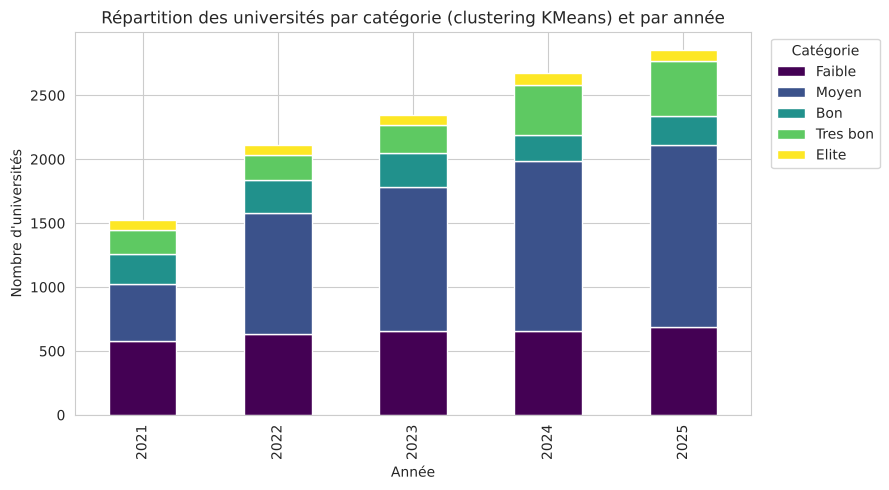

In [7]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Sous-scores THE utilisés comme variables de clustering (profil académique multidimensionnel)
cluster_features = ['the_overall', 'the_teaching', 'the_research', 'the_citations',
                     'the_industry_income', 'the_international_outlook']

X_cluster = the[cluster_features].fillna(the[cluster_features].median())
X_scaled = StandardScaler().fit_transform(X_cluster)

# On choisit k=5 pour retrouver le même nombre de catégories que l'ancien seuillage
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
the['cluster'] = kmeans.fit_predict(X_scaled)

sil = silhouette_score(X_scaled, the['cluster'])
print(f"Silhouette score (k=5) : {sil:.3f}")

# Les clusters n'ont pas d'ordre naturel -> on les trie par score THE global moyen croissant
# pour leur attribuer un label ordinal Faible -> Elite
cluster_order = the.groupby('cluster')['the_overall'].mean().sort_values().index.tolist()
labels_ordonnes = ['Faible', 'Moyen', 'Bon', 'Tres bon', 'Elite']
cluster_to_label = dict(zip(cluster_order, labels_ordonnes))

the['categorie'] = the['cluster'].map(cluster_to_label)

print("\nProfil des catégories issues du clustering :")
print(the.groupby('categorie')['the_overall'].agg(['mean', 'min', 'max', 'count']).reindex(labels_ordonnes))

fig, ax = plt.subplots()
order_cat = ['Faible', 'Moyen', 'Bon', 'Tres bon', 'Elite']
(the.groupby(['year', 'categorie']).size().unstack()[order_cat]
    .plot(kind='bar', stacked=True, ax=ax, colormap='viridis'))
ax.set_title("Répartition des universités par catégorie (clustering KMeans) et par année")
ax.set_ylabel("Nombre d'universités")
ax.set_xlabel("Année")
plt.legend(title='Catégorie', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Validation : clustering vs seuillage fixe

Comparaison, à titre de contrôle, entre la catégorie obtenue par clustering et celle qu'aurait donnée l'ancien seuillage fixe (`Elite ≥ 80, Tres bon ≥ 60, Bon ≥ 40, Moyen ≥ 20, Faible < 20`). Un fort taux d'accord confirme que les clusters retrouvent une structure cohérente avec les bandes de score usuelles, tout en étant apprises directement sur les données plutôt qu'imposées.

In [8]:
def categorize_seuil(score):
    if score >= 80: return 'Elite'
    elif score >= 60: return 'Tres bon'
    elif score >= 40: return 'Bon'
    elif score >= 20: return 'Moyen'
    else: return 'Faible'

the['categorie_seuil'] = the['the_overall'].apply(categorize_seuil)

accord = (the['categorie'] == the['categorie_seuil']).mean()
print(f"Taux d'accord clustering vs seuils fixes : {accord:.1%}\n")
print("Tableau croisé (lignes = seuils fixes, colonnes = clustering) :")
print(pd.crosstab(the['categorie_seuil'], the['categorie'],
                   rownames=['Seuils'], colnames=['Clustering'])
      .reindex(index=order_cat, columns=order_cat, fill_value=0))

Taux d'accord clustering vs seuils fixes : 75.8%

Tableau croisé (lignes = seuils fixes, colonnes = clustering) :
Clustering  Faible  Moyen  Bon  Tres bon  Elite
Seuils                                         
Faible        2571      5    0         0      0
Moyen          645   4967  513        92      0
Bon              0    289  680       992      4
Tres bon         0      0    5       345    243
Elite            0      0    0         0    158


## 7. Construction du jeu de transitions (monte / descend / stable)

On ne garde que les universités présentes sur **les 5 années** (2021-2025), afin d'avoir des transitions annuelles complètes et fiables. Pour chaque université et chaque paire d'années consécutives (2021→2022, 2022→2023, 2023→2024, 2024→2025), on calcule :
- les **features** : catégorie de départ, sous-scores THE de l'année de départ, pays, et variables croisées QS/ARWU ;
- la **cible** : la transition de catégorie observée (`Monte`, `Descend`, `Stable`).


In [9]:
full = the.groupby('name').filter(lambda g: g['year'].nunique() == 5).copy()
print(f"Universités avec historique complet 2021-2025 : {full['name'].nunique()}")

order_map = {'Faible': 0, 'Moyen': 1, 'Bon': 2, 'Tres bon': 3, 'Elite': 4}

def transition_label(cat_from, cat_to):
    a, b = order_map[cat_from], order_map[cat_to]
    if b > a: return 'Monte'
    if b < a: return 'Descend'
    return 'Stable'

# Variables croisées QS / ARWU (statiques, moyennées si doublon de nom)
qs_feat = (qs.groupby('name_key')
             .agg(qs_overall=('qs_overall', 'mean'),
                  qs_employer_reputation=('qs_employer_reputation', 'mean'),
                  qs_employment_outcomes=('qs_employment_outcomes', 'mean'))
             .reset_index())
arwu_feat = arwu.groupby('name_key').agg(arwu_score=('arwu_score', 'mean')).reset_index()

rows = []
for uni_name, g in full.groupby('name'):
    g = g.set_index('year')
    key = g['name_key'].iloc[0]
    for y1, y2 in [(2021, 2022), (2022, 2023), (2023, 2024), (2024, 2025)]:
        r1 = g.loc[y1]
        cat1, cat2 = r1['categorie'], g.loc[y2]['categorie']
        rows.append({
            'name': uni_name, 'name_key': key, 'year_from': y1, 'year_to': y2,
            'country': r1['country'], 'cat_from': cat1,
            'the_overall': r1['the_overall'], 'the_teaching': r1['the_teaching'],
            'the_research': r1['the_research'], 'the_citations': r1['the_citations'],
            'the_industry_income': r1['the_industry_income'],
            'the_international_outlook': r1['the_international_outlook'],
            'n_students': r1['n_students'], 'student_staff_ratio': r1['student_staff_ratio'],
            'pc_intl_students': r1['pc_intl_students'],
            'target': transition_label(cat1, cat2),
        })

dataset = pd.DataFrame(rows)
dataset = dataset.merge(qs_feat, on='name_key', how='left')
dataset = dataset.merge(arwu_feat, on='name_key', how='left')
cross_cols = ['qs_overall', 'qs_employer_reputation', 'qs_employment_outcomes', 'arwu_score']
dataset[cross_cols] = dataset[cross_cols].fillna(0)

print(dataset.shape)
dataset['target'].value_counts()


Universités avec historique complet 2021-2025 : 1386


(5544, 20)


target
Stable     4785
Monte       630
Descend     129
Name: count, dtype: int64

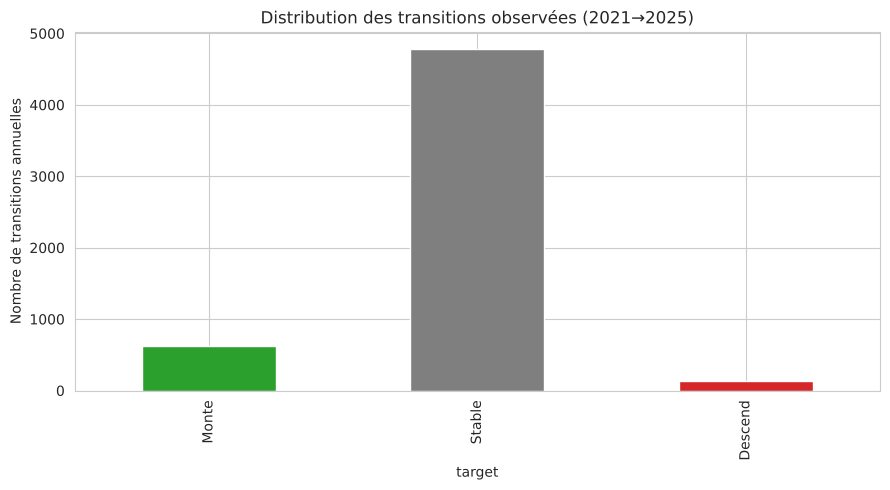

In [10]:
fig, ax = plt.subplots()
dataset['target'].value_counts().loc[['Monte', 'Stable', 'Descend']].plot(
    kind='bar', color=['#2ca02c', '#7f7f7f', '#d62728'], ax=ax)
ax.set_title("Distribution des transitions observées (2021→2025)")
ax.set_ylabel("Nombre de transitions annuelles")
plt.tight_layout()
plt.show()


## 8. Split entraînement / test (temporel)

Pour éviter toute fuite d'information, on n'utilise **pas** un split aléatoire : on entraîne sur les transitions passées (jusqu'à 2024) et on teste sur la transition **la plus récente et inédite : 2024 → 2025**. C'est la configuration la plus proche d'un usage réel (prédire l'avenir à partir du passé).

In [11]:
feature_num = ['the_overall', 'the_teaching', 'the_research', 'the_citations',
               'the_industry_income', 'the_international_outlook', 'n_students',
               'student_staff_ratio', 'pc_intl_students'] + cross_cols
feature_cat = ['cat_from', 'country']

train = dataset[dataset['year_to'] < 2025]
test = dataset[dataset['year_to'] == 2025]
print("Train :", train.shape, " | Test (2024->2025) :", test.shape)


Train : (4158, 20)  | Test (2024->2025) : (1386, 20)


## 9. Entraînement des modèles

Deux modèles sont comparés :
- une **régression logistique** (baseline linéaire, simple à interpréter) ;
- une **forêt aléatoire** (`RandomForestClassifier`), capable de capter des interactions non linéaires entre les variables.

Les classes étant déséquilibrées (beaucoup plus de `Stable` que de `Monte`/`Descend`), on utilise `class_weight='balanced'` pour ne pas que le modèle se contente de toujours prédire `Stable`.

In [12]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), feature_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), feature_cat),
])

# XGBoost exige des labels numériques : on encode la cible une seule fois
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(train['target'])
sample_weight = compute_sample_weight(class_weight='balanced', y=train['target'])
print("Classes encodées :", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

models = {
    'Régression logistique': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=300, max_depth=8,
                                        class_weight='balanced', random_state=42)),
    ]),
    'XGBoost': Pipeline([
        ('prep', preprocessor),
        ('clf', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                               objective='multi:softprob', eval_metric='mlogloss',
                               random_state=42)),
    ]),
    'Gradient Boosting': Pipeline([
        ('prep', preprocessor),
        ('clf', GradientBoostingClassifier(n_estimators=300, max_depth=3, random_state=42)),
    ]),
    'SVM': Pipeline([
        ('prep', preprocessor),
        ('clf', SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=42)),
    ]),
    'K plus proches voisins': Pipeline([
        ('prep', preprocessor),
        ('clf', KNeighborsClassifier(n_neighbors=15)),
    ]),
}

def fit_predict(name, pipe):
    """Entraîne un modèle et retourne des prédictions toujours en labels texte
    (XGBoost travaille en interne avec des labels entiers)."""
    if name == 'XGBoost':
        pipe.fit(train[feature_num + feature_cat], y_train_enc, clf__sample_weight=sample_weight)
        pred_enc = pipe.predict(test[feature_num + feature_cat])
        pred = label_encoder.inverse_transform(pred_enc)
    else:
        pipe.fit(train[feature_num + feature_cat], train['target'])
        pred = pipe.predict(test[feature_num + feature_cat])
    return pred

results = {}
for name, pipe in models.items():
    pred = fit_predict(name, pipe)
    acc = accuracy_score(test['target'], pred)
    results[name] = (pipe, pred, acc)
    print(f"\n=== {name} — accuracy = {acc:.3f} ===")
    print(classification_report(test['target'], pred, digits=2))


Classes encodées : {'Descend': np.int64(0), 'Monte': np.int64(1), 'Stable': np.int64(2)}



=== Régression logistique — accuracy = 0.535 ===
              precision    recall  f1-score   support

     Descend       0.05      0.89      0.09        18
       Monte       0.19      0.84      0.31        91
      Stable       0.98      0.51      0.67      1277

    accuracy                           0.53      1386
   macro avg       0.41      0.74      0.36      1386
weighted avg       0.92      0.53      0.64      1386




=== Random Forest — accuracy = 0.555 ===
              precision    recall  f1-score   support

     Descend       0.02      0.39      0.04        18
       Monte       0.22      0.89      0.35        91
      Stable       0.98      0.53      0.69      1277

    accuracy                           0.55      1386
   macro avg       0.40      0.60      0.36      1386
weighted avg       0.91      0.55      0.66      1386




=== XGBoost — accuracy = 0.836 ===
              precision    recall  f1-score   support

     Descend       0.03      0.06      0.03        18
       Monte       0.30      0.66      0.41        91
      Stable       0.96      0.86      0.91      1277

    accuracy                           0.84      1386
   macro avg       0.43      0.52      0.45      1386
weighted avg       0.90      0.84      0.86      1386




=== Gradient Boosting — accuracy = 0.905 ===
              precision    recall  f1-score   support

     Descend       0.20      0.06      0.09        18
       Monte       0.33      0.21      0.26        91
      Stable       0.93      0.97      0.95      1277

    accuracy                           0.90      1386
   macro avg       0.49      0.41      0.43      1386
weighted avg       0.88      0.90      0.89      1386




=== SVM — accuracy = 0.608 ===
              precision    recall  f1-score   support

     Descend       0.03      0.44      0.06        18
       Monte       0.21      0.85      0.34        91
      Stable       0.98      0.59      0.74      1277

    accuracy                           0.61      1386
   macro avg       0.41      0.63      0.38      1386
weighted avg       0.91      0.61      0.70      1386


=== K plus proches voisins — accuracy = 0.921 ===
              precision    recall  f1-score   support

     Descend       0.00      0.00      0.00        18
       Monte       0.42      0.05      0.10        91
      Stable       0.93      1.00      0.96      1277

    accuracy                           0.92      1386
   macro avg       0.45      0.35      0.35      1386
weighted avg       0.88      0.92      0.89      1386



## 10. Matrice de confusion (KNN)

On regarde en détail où le meilleur modèle se trompe : la confusion la plus fréquente est généralement entre `Stable` et les classes minoritaires, ce qui est attendu vu le déséquilibre des classes.

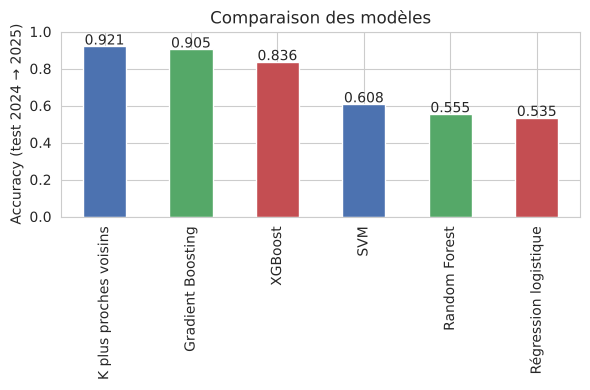

In [13]:
acc_series = pd.Series({name: res[2] for name, res in results.items()}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 4))
acc_series.plot(kind='bar', color=['#4c72b0', '#55a868', '#c44e52'], ax=ax)
ax.set_ylabel('Accuracy (test 2024 → 2025)')
ax.set_title('Comparaison des modèles')
ax.set_ylim(0, 1)
for i, v in enumerate(acc_series):
    ax.text(i, v + 0.01, f"{v:.3f}", ha='center')
plt.tight_layout()
plt.show()


## 11. Importance des variables

Quelles variables pèsent le plus dans la prédiction d'une transition de catégorie ?

Meilleur modèle : K plus proches voisins (accuracy = 0.921)


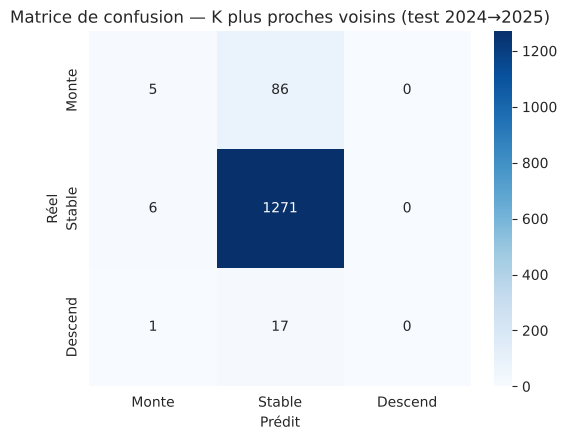

In [14]:
best_name = max(results, key=lambda n: results[n][2])
best_pipe, best_pred, best_acc = results[best_name]
print(f"Meilleur modèle : {best_name} (accuracy = {best_acc:.3f})")

labels = ['Monte', 'Stable', 'Descend']
cm = confusion_matrix(test['target'], best_pred, labels=labels)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
ax.set_title(f"Matrice de confusion — {best_name} (test 2024→2025)")
plt.tight_layout()
plt.show()


## 12. Application : prédire la transition 2025 → 2026

On applique le modèle entraîné aux données 2025 (les plus récentes) pour obtenir une **vraie prédiction future**, sans vérité terrain disponible : quelles universités sont pressenties pour monter ou descendre de catégorie en 2026 ?

In [15]:
future_rows = []
for uni_name, g in full.groupby('name'):
    g = g.set_index('year')
    r = g.loc[2025]
    key = r['name_key']
    future_rows.append({
        'name': uni_name, 'name_key': key, 'country': r['country'], 'cat_from': r['categorie'],
        'the_overall': r['the_overall'], 'the_teaching': r['the_teaching'],
        'the_research': r['the_research'], 'the_citations': r['the_citations'],
        'the_industry_income': r['the_industry_income'],
        'the_international_outlook': r['the_international_outlook'],
        'n_students': r['n_students'], 'student_staff_ratio': r['student_staff_ratio'],
        'pc_intl_students': r['pc_intl_students'],
    })

future = pd.DataFrame(future_rows)
future = future.merge(qs_feat, on='name_key', how='left').merge(arwu_feat, on='name_key', how='left')
future[cross_cols] = future[cross_cols].fillna(0)

future['prediction_2026'] = best_pipe.predict(future[feature_num + feature_cat])
proba = best_pipe.predict_proba(future[feature_num + feature_cat])
future['confiance'] = proba.max(axis=1)

print(future['prediction_2026'].value_counts())


prediction_2026
Stable    1383
Monte        3
Name: count, dtype: int64


In [16]:
print("=== Top 10 universités pressenties pour MONTER de catégorie en 2026 ===")
display(future[future['prediction_2026'] == 'Monte']
        .sort_values('confiance', ascending=False)
        [['name', 'country', 'cat_from', 'the_overall', 'confiance']].head(10))

print("\n=== Top 10 universités pressenties pour DESCENDRE de catégorie en 2026 ===")
display(future[future['prediction_2026'] == 'Descend']
        .sort_values('confiance', ascending=False)
        [['name', 'country', 'cat_from', 'the_overall', 'confiance']].head(10))


=== Top 10 universités pressenties pour MONTER de catégorie en 2026 ===


,name,country,cat_from,the_overall,confiance
221,Florida Institute of Technology,United States,Moyen,34.0,0.533333
1175,University of Rennes 1,France,Moyen,38.0,0.533333
1130,University of Nairobi,Kenya,Faible,10.0,0.466667



=== Top 10 universités pressenties pour DESCENDRE de catégorie en 2026 ===


,name,country,cat_from,the_overall,confiance
